# Client Propensity

**Questions:** which new client profiles are likely to grow (5 seats in a year, 10 in two years), which existing clients
are likely to keep adding seats or branch into new departments, and, for a brand-new client, both at once.

This notebook only *shows* results. The work happens in the pipeline (see `README.md` and `DOCUMENTATION.md`):

| Step | File | What it does |
|---|---|---|
| 1 Format | `mi_pipeline/step1_format.py` | load the 4 raw files, clean types / IDs / dates |
| 2 Merge | `mi_pipeline/step2_merge.py` | StaffCentral departments (JP Category; blanks imputed from JP Title, Designation or old Department), industry (dashboard's 18 groups), region |
| 3 Data engineering | `mi_pipeline/step3_features.py` | headcount timeline, account summary, launch size, department history, seat measures, snapshots |
| 4 Analysis | `mi_pipeline/step4_branching.py`, `step4_propensity.py` | branching patterns; propensity models, scorecard, client list, prospect profiles |
| 5 Output | `mi_pipeline/step5_output.py` | Excel workbook (saved in the local data folder), charts |
| 5b Extract | `mi_pipeline/step5_extract.py` | extract for the Account Priority Dashboard (local data folder) |

Settings live in `config.py`. To run everything without the notebook: `uv run python run_pipeline.py`.

In [1]:
%load_ext autoreload
# pick up edits to config.py / mi_pipeline without restarting the kernel
%autoreload 2
import pandas as pd
import matplotlib.pyplot as plt
from run_pipeline import run_all
from mi_pipeline import step5_output as out

pd.set_option("display.max_colwidth", None)
res = run_all(write_excel=True, write_extract=True)   # workbook + separate dashboard extract (~45s on first run)
F, B, P = res["features"], res["branching"], res["propensity"]

Data as of 2026-11-12 | raw data: C:\Users\Alfonso(FonsoP)Panli\Desktop\Projects\Client Propensity\Data
[1 format] engagement rows 30837 | seat churn rows 30772 | MyStaff accounts 2874 | StaffCentral staffers 20769 (75 duplicate CSID rows dropped)
[2 merge] Exec Services staff with no JP Category: 4893, of which 2169 inferred from Designation
[2 merge] engagements with a role group: 99.4% | department certain (Engagement ID matches): 62.6% | 'Exec Services - Other' rows: 4269
[2 merge] industry (18 groups): 1846 from Industry Hubspot, 490 from Roll Up, 538 blank
[2 merge] region: 2575 of 2874 accounts | country: {'Australia': 1427, 'United States': 654, 'Unknown': 299, 'Other': 208, 'United Kingdom': 173, 'New Zealand': 59, 'Canada': 54}
[3 features] hires 30837 | exits 23359 | active 7478 | timeline rows 29770 for 2481 accounts
[3 features] summary: 2481 accounts | active 1100 | churn gaps 1472, backfill gaps 92 | reached 5 seats (held): 562
[3 features] client accounts: 2325 (156 non

## 1. New clients: profile scorecard

One line per client profile (industry, country, starting department, launch size). **Growth** = reach and hold
5 seats within a year, and 10 seats within two years; **branching** = add a department in year 1. Each score has a band
(thirds of past clients) and a *why*. Check what each band actually delivered before relying on it.

In [2]:
checks = {"5 seats in 1y": (P["growth_check"], P["growth_auc"]), **P["milestone_checks"],
          "New dept in year 1": (P["branch_check"], P["branch_auc"])}
print(" | ".join(f"{k}: AUC {a:.2f}" for k, (_, a) in checks.items()), "  (0.5 = coin flip, 0.7+ = useful)")
display(pd.concat({k: chk for k, (chk, _) in checks.items()}, axis=1))

5 seats in 1y: AUC 0.72 | New client reaches 10 seats in 2y: AUC 0.83 | New dept in year 1: AUC 0.62   (0.5 = coin flip, 0.7+ = useful)


5 seats in 1y                       New client reaches 10 seats in 2y  \
                rows actual_rate avg_score                              rows   
band                                                                           
Low              341       0.041     0.040                               258   
Medium           345       0.064     0.065                               257   
High             344       0.183     0.184                               258   

                             New dept in year 1                        
       actual_rate avg_score               rows actual_rate avg_score  
band                                                                   
Low          0.012     0.013                362       0.221     0.155  
Medium       0.023     0.023                362       0.257     0.263  
High         0.105     0.103                363       0.377     0.444

In [3]:
# Traits that move the chances (percentage points vs the average client)
display(P["new_factors"])

,factor,level,rows_growth,growth_vs_avg_pts,rows_branch,branch_vs_avg_pts,reach10_vs_avg_pts
5,country,United States,291.0,1.1,320,4.2,1.0
0,country,Australia,567.0,0.1,588,-1.8,-0.1
4,country,United Kingdom,87.0,-0.8,89,-2.6,-2.6
3,country,Other,27.0,-2.3,30,-3.2,-1.0
2,country,New Zealand,33.0,-3.6,34,4.2,-1.9
1,country,Canada,25.0,-5.3,26,-4.8,-1.8
9,industry_fit,Education & Training,26.0,6.2,27,-6.3,1.4
22,industry_fit,Unknown,21.0,5.3,28,4.9,NaN
12,industry_fit,"Hospitality, Travel & Leisure",29.0,4.5,35,1.7,3.2
20,industry_fit,Technology,126.0,2.6,132,-2.4,0.4


In [4]:
display(P["new_client_scorecard"][["line_item", "outlook", "growth_why", "clients_seen", "actual_growth_rate"]].head(20))

,line_item,outlook,growth_why,clients_seen,actual_growth_rate
0,"Unknown | United States | starts in Exec Services - BPO Voice | launch 3-4 staff -> 5 seats in 1y: High (73%) | 10 seats in 2y: High (46%) | New dept in 1y: High (70%) | likely next: Exec Services - Administrative 15% (1.6x), Accounting Support Services 10% (0.6x)",Grow + expand,launch 3-4 staff; starts in Exec Services - BPO Voice,1,NaN
1,"Unknown | Australia | starts in Exec Services - Accounting | launch 3-4 staff -> 5 seats in 1y: High (71%) | 10 seats in 2y: High (18%) | New dept in 1y: High (71%) | likely next: Accounting Support Services 36% (2.4x), Exec Services - Other 14% (2.0x)",Grow + expand,launch 3-4 staff; starts in Exec Services - Accounting,2,1.0
2,"Technology | United States | starts in Technical Support Services | launch 3-4 staff -> 5 seats in 1y: High (67%) | 10 seats in 2y: High (35%) | New dept in 1y: High (56%) | likely next: Exec Services - BPO Voice 25% (3.4x), Engineering 19% (3.0x)",Grow + expand,launch 3-4 staff; industry: Technology,1,1.0
3,"Technology | United States | starts in Exec Services - BPO Voice | launch 3-4 staff -> 5 seats in 1y: High (67%) | 10 seats in 2y: High (44%) | New dept in 1y: High (61%) | likely next: Exec Services - Administrative 15% (1.6x), Accounting Support Services 10% (0.6x)",Grow + expand,launch 3-4 staff; industry: Technology,1,1.0
4,"Hospitality, Travel & Leisure | United Kingdom | starts in Technical Support Services | launch 3-4 staff -> 5 seats in 1y: High (66%) | 10 seats in 2y: High (22%) | New dept in 1y: High (53%) | likely next: Exec Services - BPO Voice 25% (3.4x), Engineering 19% (3.0x)",Grow + expand,"launch 3-4 staff; industry: Hospitality, Travel & Leisure",1,0.0
5,"Unknown | United States | starts in Marketing | launch 3-4 staff -> 5 seats in 1y: High (65%) | 10 seats in 2y: High (47%) | New dept in 1y: High (57%) | likely next: Exec Services - Virtual Assistant 18% (3.1x), Exec Services - Administrative 18% (1.8x)",Grow + expand,launch 3-4 staff; country: United States,1,NaN
6,"Hospitality, Travel & Leisure | Australia | starts in Accounting Support Services | launch 3-4 staff -> 5 seats in 1y: High (65%) | 10 seats in 2y: High (27%) | New dept in 1y: High (42%) | likely next: Exec Services - Administrative 16% (1.7x), Exec Services - Accounting 15% (2.4x)",Grow + expand,"launch 3-4 staff; industry: Hospitality, Travel & Leisure",1,0.0
7,"Technology | Australia | starts in Technical Support Services | launch 3-4 staff -> 5 seats in 1y: High (64%) | 10 seats in 2y: High (29%) | New dept in 1y: High (48%) | likely next: Exec Services - BPO Voice 25% (3.4x), Engineering 19% (3.0x)",Grow + expand,launch 3-4 staff; industry: Technology,3,1.0
8,"Hospitality, Travel & Leisure | United States | starts in Other | launch 3-4 staff -> 5 seats in 1y: High (64%) | 10 seats in 2y: High (41%) | New dept in 1y: High (66%) | likely next: Accounting Support Services 15%, Exec Services - Administrative 10% (overall)",Grow + expand,"launch 3-4 staff; industry: Hospitality, Travel & Leisure",2,0.5
9,"Technology | Australia | starts in Exec Services - BPO Voice | launch 3-4 staff -> 5 seats in 1y: High (64%) | 10 seats in 2y: High (37%) | New dept in 1y: High (53%) | likely next: Exec Services - Administrative 15% (1.6x), Accounting Support Services 10% (0.6x)",Grow + expand,launch 3-4 staff; industry: Technology,1,1.0


In [5]:
# Score any brand-new client
scorer = P["scorer"]
display(scorer.score("Real Estate", "Australia", start_dept="Real Estate", launch_size=1))
display(scorer.score("Technology", region="US", start_dept="Software Development", launch_size=3))

,line_item,outlook,p_growth,growth_band,growth_why,p_reach_10_730d,band_reach_10_730d,why_reach_10_730d,p_branch,branch_band,likely_first_new_dept,likely_first_new_dept_by_lift
0,"Real Estate | Australia | starts in Exec Services - Real Estate | launch 1-2 staff -> 5 seats in 1y: Low (5%) | 10 seats in 2y: Medium (3%) | New dept in 1y: Low (14%) | likely next: Marketing 18% (3.1x), Exec Services - Legal Specialist 9% (8.1x)",Low propensity,0.047012,Low,,0.027911,Medium,starts in Exec Services - Real Estate,0.144111,Low,"Marketing 18% (3.1x), Exec Services - Legal Specialist 9% (8.1x)","Exec Services - Facilities Management 13.5x (9%), Exec Services - Legal Specialist 8.1x (9%)"


,line_item,outlook,p_growth,growth_band,growth_why,p_reach_10_730d,band_reach_10_730d,why_reach_10_730d,p_branch,branch_band,likely_first_new_dept,likely_first_new_dept_by_lift
0,"Technology | United States | starts in Software Development | launch 3-4 staff -> 5 seats in 1y: High (52%) | 10 seats in 2y: High (24%) | New dept in 1y: High (52%) | likely next: Technical Support Services 25% (6.2x), Engineering 15% (2.4x)",Grow + expand,0.518723,High,launch 3-4 staff; industry: Technology,0.244136,High,launch 3-4 staff; country: United States,0.523583,High,"Technical Support Services 25% (6.2x), Engineering 15% (2.4x)","SQA Services 14.8x (10%), Exec Services - IT Software Development 11.1x (5%)"


## 2. Existing clients: who will keep growing

One line per active client: chance of having **more seats** in 12 months and of adding a **department it has never had**,
each compared with clients of a similar size (**vs peers**) and with a *why*, plus the most likely next department
(share, and lift = how unusual that is for this client).

In [6]:
print(f"Seat growth AUC {P['seat_auc']:.2f} | New department AUC {P['organic_auc']:.2f}")
display(pd.concat({"More seats in 12m": P["seat_check"], "New dept in 12m": P["organic_check"]}, axis=1))
display(P["seat_factors"])
display(P["organic_factors"])

Seat growth AUC 0.69 | New department AUC 0.70


More seats in 12m                       New dept in 12m              \
                    rows actual_rate avg_score            rows actual_rate   
band                                                                         
Low                 3744       0.131     0.116            3744       0.092   
Medium              3743       0.200     0.211            3743       0.199   
High                3744       0.412     0.414            3744       0.364   

                  
       avg_score  
band              
Low        0.097  
Medium     0.183  
High       0.376

,factor,level,rows,avg_score,vs_average_pts
38,age_years,low (10th pct) = 0.49,NaN,0.286,3.8
39,age_years,typical (median) = 1.97,NaN,0.258,1.1
40,age_years,high (90th pct) = 5.67,NaN,0.197,-5.1
20,country,United States,3089.0,0.275,2.7
21,country,United Kingdom,575.0,0.253,0.5
19,country,Australia,6633.0,0.245,-0.2
24,country,Canada,243.0,0.205,-4.2
23,country,New Zealand,333.0,0.184,-6.4
22,country,Other,358.0,0.130,-11.7
47,hires_180d,low (10th pct) = 0.00,NaN,0.256,0.9


,factor,level,rows,avg_score,vs_average_pts
38,age_years,low (10th pct) = 0.49,NaN,0.263,4.5
39,age_years,typical (median) = 1.97,NaN,0.231,1.2
40,age_years,high (90th pct) = 5.67,NaN,0.162,-5.7
19,country,Australia,6633.0,0.227,0.9
20,country,United States,3089.0,0.222,0.3
21,country,United Kingdom,575.0,0.208,-1.0
24,country,Canada,243.0,0.203,-1.6
23,country,New Zealand,333.0,0.149,-6.9
22,country,Other,358.0,0.132,-8.6
47,hires_180d,low (10th pct) = 0.00,NaN,0.225,0.7


In [7]:
lst = P["organic_client_list"]
display(pd.crosstab(lst["seat_growth_band"], lst["band"], rownames=["seat growth"], colnames=["new department"]))
display(lst[["line_item", "likely_next_dept_by_lift", "seat_why"]].head(15))

new department,Low,Medium,High
seat growth,,,
Low,249,86,3
Medium,72,149,49
High,10,116,268


,line_item,likely_next_dept_by_lift,seat_why
0,"FOURTHENT | Technology | 134 seats, 20 dept(s) -> More seats in 12m: High (83%, 1.4x peers) | New dept in 12m: High (86%, 1.4x peers) | likely next: Exec Services - Administrative 14% (0.6x), Marketing 9% (1.0x) | why: 134 seats; +6 seats in last 6m","Sales 3.8x (5%), Exec Services - Creative, Design & Multimedia 2.3x (4%)",134 seats; +6 seats in last 6m
1,"HALOMD | Healthcare & Wellness | 124 seats, 6 dept(s) -> More seats in 12m: High (92%, 1.5x peers) | New dept in 12m: High (86%, 1.4x peers) | likely next: Exec Services - Administrative 8% (0.7x), Exec Services - Virtual Assistant 6% (0.8x) | why: 124 seats; +6 seats in last 6m","Exec Services - Legal Specialist 2.0x (6%), Exec Services - Human Resources 1.8x (4%)",124 seats; +6 seats in last 6m
2,"QUIKAID | Legal | 119 seats, 13 dept(s) -> More seats in 12m: High (76%, 1.3x peers) | New dept in 12m: High (81%, 1.4x peers) | likely next: Accounting Support Services 12% (0.7x), Exec Services - Accounting 10% (0.8x) | why: 119 seats; +28 seats in last 6m","Business Analyst 1.6x (4%), Exec Services - Data Science / Analytics 1.4x (4%)",119 seats; +28 seats in last 6m
3,"PRECOR | Retail & Consumer Goods | 57 seats, 13 dept(s) -> More seats in 12m: High (71%, 1.2x peers) | New dept in 12m: High (81%, 1.3x peers) | likely next: Exec Services - Virtual Assistant 10% (0.7x), Engineering 7% (0.6x) | why: 57 seats; started in: Exec Services - Accounting","SQA Services 1.7x (3%), Exec Services - BPO Healthcare 1.5x (3%)",57 seats; country: United States
4,"ARRIVIA | Hospitality, Travel & Leisure | 347 seats, 23 dept(s) -> More seats in 12m: High (70%, 1.2x peers) | New dept in 12m: High (80%, 1.3x peers) | likely next: Exec Services - BPO Collections 8% (2.0x), Software Development 7% (0.6x) | why: 347 seats; +41 seats in last 6m","Data Capture Services 3.6x (6%), Exec Services - Facilities Management 3.1x (3%)",347 seats; +41 seats in last 6m
5,"PARKSTREET | Retail & Consumer Goods | 124 seats, 19 dept(s) -> More seats in 12m: High (69%, 1.1x peers) | New dept in 12m: High (75%, 1.2x peers) | likely next: Software Development 8% (0.6x), Exec Services - Data Science / Analytics 8% (1.5x) | why: 124 seats; started in: Exec Services - Other","Talent Acquisition 2.9x (3%), Sales 2.9x (5%)",124 seats; country: United States
6,"EVOLVHEALTH | Healthcare & Wellness | 16 seats, 2 dept(s) -> More seats in 12m: High (75%, 1.6x peers) | New dept in 12m: High (75%, 1.9x peers) | likely next: Accounting Support Services 11% (0.9x), Exec Services - Accounting 9% (1.1x) | why: 16 seats; started in: Exec Services - Administrative","Exec Services - Legal Specialist 1.2x (3%), Exec Services - BPO Non-Voice/Back-Office 1.1x (5%)",16 seats; +10 seats in last 6m
7,"OOMA | Technology | 30 seats, 4 dept(s) -> More seats in 12m: High (77%, 1.3x peers) | New dept in 12m: High (74%, 1.2x peers) | likely next: Exec Services - Accounting 8% (1.1x), Exec Services - Administrative 8% (0.8x) | why: 30 seats; +12 seats in last 6m","Exec Services - BPO Collections 2.4x (4%), Exec Services - Data Science / Analytics 2.3x (4%)",30 seats; +12 seats in last 6m
8,"FINDEX | Financial Services | 143 seats, 13 dept(s) -> More seats in 12m: High (79%, 1.3x peers) | New dept in 12m: High (73%, 1.2x peers) | likely next: Software Development 8% (0.8x), Exec Services - BPO Voice 8% (0.5x) | why: 143 seats; +2 seats in last 6m","Exec Services - Creative, Design & Multimedia 2.2x (3%), Exec Services - IT Network Systems/Support 2.0x (3%)",143 seats; +2 seats in last 6m
9,"DEFERITUS | Technology | 90 seats, 12 dept(s) -> More seats in 12m: High (79%, 1.3x peers) | New dept in 12m: High (73%, 1.2x peers) | likely next: Exec Services - Data Science / Analytics 6% (1.6x), Marketing 6% (0.7x) | why: 90 seats; started in: Exec Services - Administrative","Sales 3.2x (4%), Data Capture Services 2.8x (4%)",90 seats; country: United States


In [8]:
# Under 10 seats, most above their peers: the less obvious expansion targets
display(P["organic_rising"][["line_item"]])

,line_item
0,"AUAITKEN | Unknown | 2 seats, 1 dept(s) -> More seats in 12m: High (53%, 2.7x peers) | New dept in 12m: High (38%, 2.6x peers) | likely next: Accounting Support Services 11% (1.0x), Exec Services - Accounting 9% (1.2x) | why: started in: Exec Services - Administrative; 0.1 yrs with us"
1,"ISCAFOODINDEQP | Manufacturing & Industrial | 2 seats, 2 dept(s) -> More seats in 12m: High (36%, 1.9x peers) | New dept in 12m: High (36%, 2.5x peers) | likely next: Accounting Support Services 11% (0.9x), Exec Services - Accounting 8% (1.0x) | why: started in: Exec Services - Administrative; industry: Manufacturing & Industrial"
2,"OPISEKURA | Unknown | 2 seats, 2 dept(s) -> More seats in 12m: High (50%, 2.6x peers) | New dept in 12m: High (33%, 2.2x peers) | likely next: Accounting Support Services 12% (1.0x), Exec Services - Virtual Assistant 6% (0.9x) | why: started in: Exec Services - Administrative; 0.6 yrs with us"
3,"OPINOBELUS | Manufacturing & Industrial | 2 seats, 3 dept(s) -> More seats in 12m: High (30%, 1.6x peers) | New dept in 12m: High (33%, 2.2x peers) | likely next: Marketing 11% (2.6x), Exec Services - Legal Specialist 7% (3.2x) | why: industry: Manufacturing & Industrial; 1.5 yrs with us"
4,"AUKRNETA | Construction & Engineering | 2 seats, 2 dept(s) -> More seats in 12m: High (30%, 1.5x peers) | New dept in 12m: High (32%, 2.2x peers) | likely next: Exec Services - Accounting 10% (1.2x), Exec Services - BPO Voice 8% (0.9x) | why: started in: Exec Services - Administrative; 0.6 yrs with us"
5,"AMESDIRECT | Manufacturing & Industrial | 1 seats, 1 dept(s) -> More seats in 12m: High (27%, 1.4x peers) | New dept in 12m: High (32%, 2.2x peers) | likely next: Accounting Support Services 11% (1.0x), Exec Services - Accounting 9% (1.2x) | why: started in: Exec Services - Administrative; industry: Manufacturing & Industrial"
6,"AUFASTPRINTING | Unknown | 2 seats, 1 dept(s) -> More seats in 12m: High (41%, 2.1x peers) | New dept in 12m: High (32%, 2.2x peers) | likely next: Accounting Support Services 9% (0.8x), Exec Services - Accounting 8% (1.1x) | why: started in: Exec Services - BPO Voice; 0.2 yrs with us"
7,"USSTRUXURENORCA | Unknown | 2 seats, 2 dept(s) -> More seats in 12m: High (48%, 2.5x peers) | New dept in 12m: High (32%, 2.1x peers) | likely next: Exec Services - BPO Non-Voice/Back-Office 7% (1.7x), Technical Support Services 7% (2.0x) | why: 0.2 yrs with us; +2 seats in last 6m"
8,"TRUSTWELL | Unknown | 2 seats, 2 dept(s) -> More seats in 12m: High (48%, 2.5x peers) | New dept in 12m: High (31%, 2.1x peers) | likely next: Accounting Support Services 9% (0.8x), Exec Services - Administrative 9% (0.9x) | why: 0.3 yrs with us; +2 seats in last 6m"
9,"USJOHNSONRV2 | Unknown | 2 seats, 1 dept(s) -> More seats in 12m: High (46%, 2.4x peers) | New dept in 12m: High (31%, 2.1x peers) | likely next: Accounting Support Services 9% (0.8x), Exec Services - Accounting 8% (1.1x) | why: started in: Exec Services - BPO Voice; 0.2 yrs with us"


## 3. Branching patterns

Where clients start, what they add first, how fast, and which departments go together.

,accounts,pct_launched_multi_dept,pct_branched_ever,median_days_to_first_branch_if_branched,median_depts_ever,top_first_new_depts
start_dept,,,,,,
Accounting Support Services,475,0.084,0.299,177.0,1.0,Exec Services - Other 13% | Exec Services - Administrative 13% | Exec Services - Accounting 11%
Exec Services - Other,286,0.231,0.402,140.0,1.0,Accounting Support Services 18% | Exec Services - Virtual Assistant 10% | Exec Services - BPO Voice 9%
Exec Services - Virtual Assistant,192,0.188,0.354,175.0,1.0,Accounting Support Services 19% | Exec Services - Other 15% | Exec Services - Administrative 9%
Software Development,150,0.080,0.380,259.0,1.0,SQA Services 28% | Technical Support Services 18% | Creative and Design Services 7%
Exec Services - BPO Voice,145,0.324,0.462,88.0,2.0,Exec Services - Administrative 15% | Accounting Support Services 10% | Exec Services - Other 9%
Exec Services - Administrative,141,0.163,0.411,182.0,2.0,Accounting Support Services 31% | Exec Services - Other 12% | Exec Services - BPO Voice 9%
Exec Services - Real Estate,129,0.093,0.194,172.0,1.0,Exec Services - Other 20% | Accounting Support Services 16% | Creative and Design Services 12%
Engineering,113,0.080,0.354,308.0,1.0,Accounting Support Services 22% | Marketing 12% | Exec Services - Other 8%
Marketing,96,0.177,0.344,175.0,1.0,Exec Services - Virtual Assistant 15% | Software Development 12% | Exec Services - Marketing/Content 12%


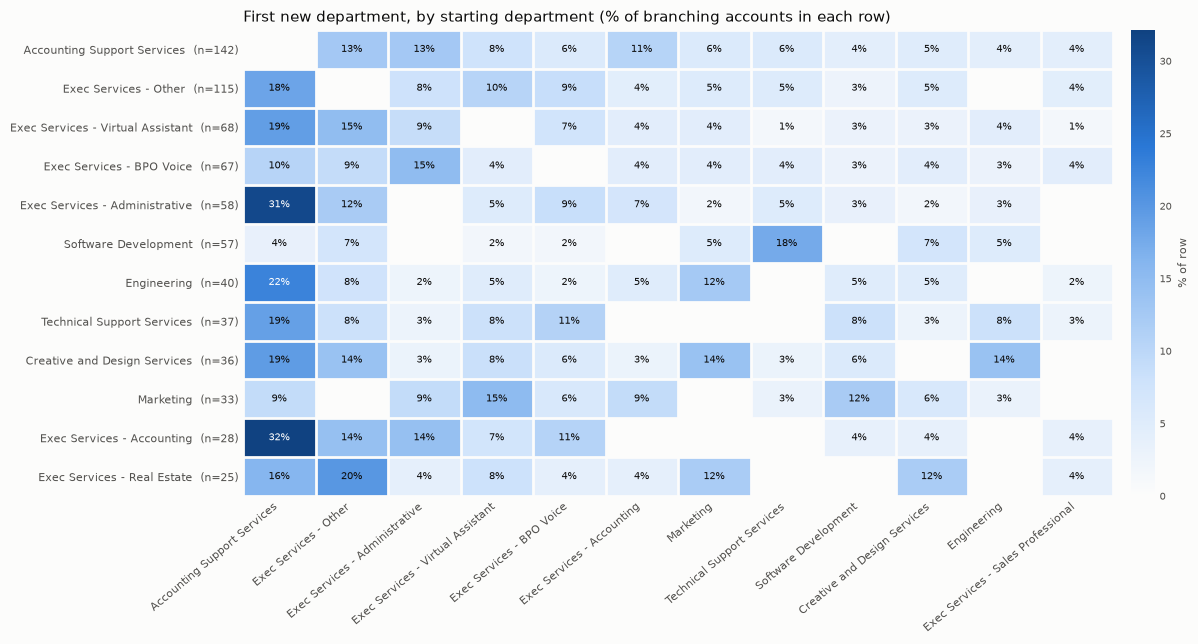

,path,accounts
0,Accounting Support Services -> Exec Services - Accounting,11
1,Exec Services - Other -> Accounting Support Services,10
2,Accounting Support Services -> Exec Services - Virtual Assistant,8
3,Accounting Support Services -> Exec Services - Administrative,8
4,Software Development -> SQA Services,8
5,Exec Services - Virtual Assistant -> Accounting Support Services,7
6,Software Development -> Technical Support Services,7
7,Engineering -> Accounting Support Services,7
8,Exec Services - Administrative -> Accounting Support Services,7
9,Exec Services - Other -> Exec Services - Virtual Assistant,5


,accounts,pct_branched_ever,median_depts_ever,top_starting_depts,top_first_new_depts
industry_group,,,,,
Real Estate,393,0.354,1.0,Exec Services - Real Estate 27% | Exec Services - Other 17% | Accounting Support Services 14%,Accounting Support Services 17% | Exec Services - Virtual Assistant 13% | Exec Services - Other 12%
Technology,337,0.445,2.0,Software Development 19% | Technical Support Services 18% | Exec Services - Other 14%,Technical Support Services 12% | Software Development 9% | SQA Services 9%
Construction & Engineering,188,0.383,1.0,Engineering 32% | Accounting Support Services 24% | Exec Services - Administrative 10%,Accounting Support Services 19% | Engineering 14% | Exec Services - Accounting 11%
Financial Services,185,0.357,1.0,Exec Services - Other 23% | Accounting Support Services 21% | Exec Services - Accounting 12%,Accounting Support Services 17% | Exec Services - Other 14% | Exec Services - Accounting 12%
Accounting,158,0.165,1.0,Accounting Support Services 85% | Exec Services - Other 3% | Exec Services - Administrative 3%,Exec Services - Administrative 19% | Exec Services - Other 15% | Accounting Support Services 15%
Retail & Consumer Goods,146,0.432,1.5,Accounting Support Services 20% | Exec Services - Virtual Assistant 12% | Exec Services - Other 10%,Accounting Support Services 16% | Exec Services - BPO Voice 14% | Exec Services - Other 11%
Manufacturing & Industrial,125,0.512,2.0,Accounting Support Services 16% | Engineering 14% | Exec Services - BPO Voice 13%,Accounting Support Services 27% | Exec Services - BPO Voice 12% | Engineering 8%
"Marketing, Media & Creative",123,0.390,1.0,Software Development 17% | Marketing 15% | Creative and Design Services 14%,Marketing 21% | Creative and Design Services 10% | Exec Services - Other 10%
Professional Services,102,0.392,1.0,Exec Services - Other 17% | Accounting Support Services 11% | Exec Services - Virtual Assistant 8%,Accounting Support Services 12% | Exec Services - Recruitment 8% | SQA Services 8%


In [9]:
display(B["start_dept_summary"])
out.plot_transitions(B); plt.show()
display(B["top_paths"])
display(B["branch_by_industry"])

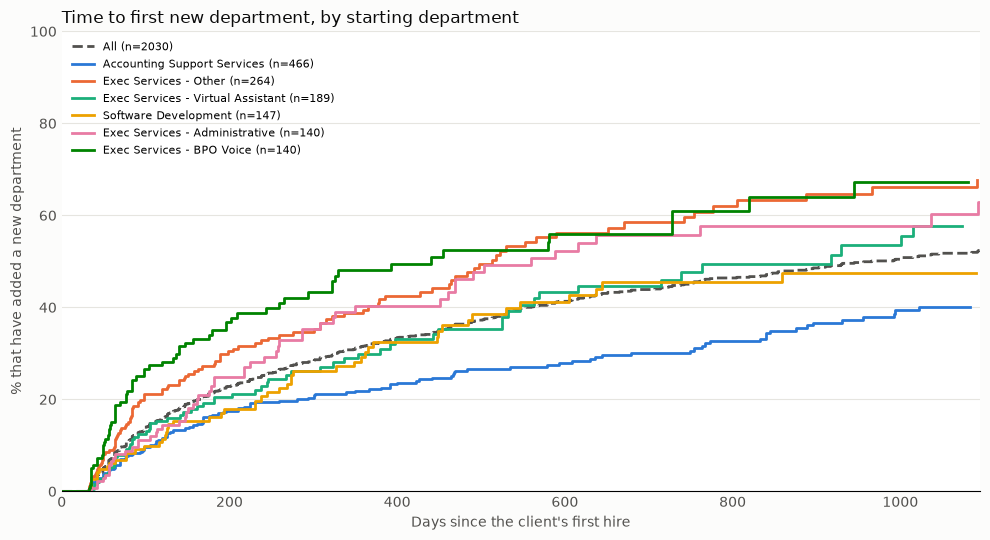

,accounts,pct_branched_180d,pct_branched_365d,pct_branched_730d,median_days_to_branch
start_dept,,,,,
All client accounts,2030,0.214,0.319,0.448,966.0
Accounting Support Services,466,0.167,0.219,0.301,1683.0
Exec Services - Other,264,0.272,0.402,0.585,513.0
Exec Services - Virtual Assistant,189,0.192,0.300,0.460,917.0
Software Development,147,0.162,0.313,0.455,1155.0
Exec Services - Administrative,140,0.229,0.404,0.557,560.0
Exec Services - BPO Voice,140,0.350,0.481,0.609,440.0
Exec Services - Real Estate,125,0.120,0.198,0.295,1738.0
Engineering,111,0.149,0.227,0.373,1367.0


In [10]:
out.plot_time_to_branch(B); plt.show()
display(B["time_to_branch"])

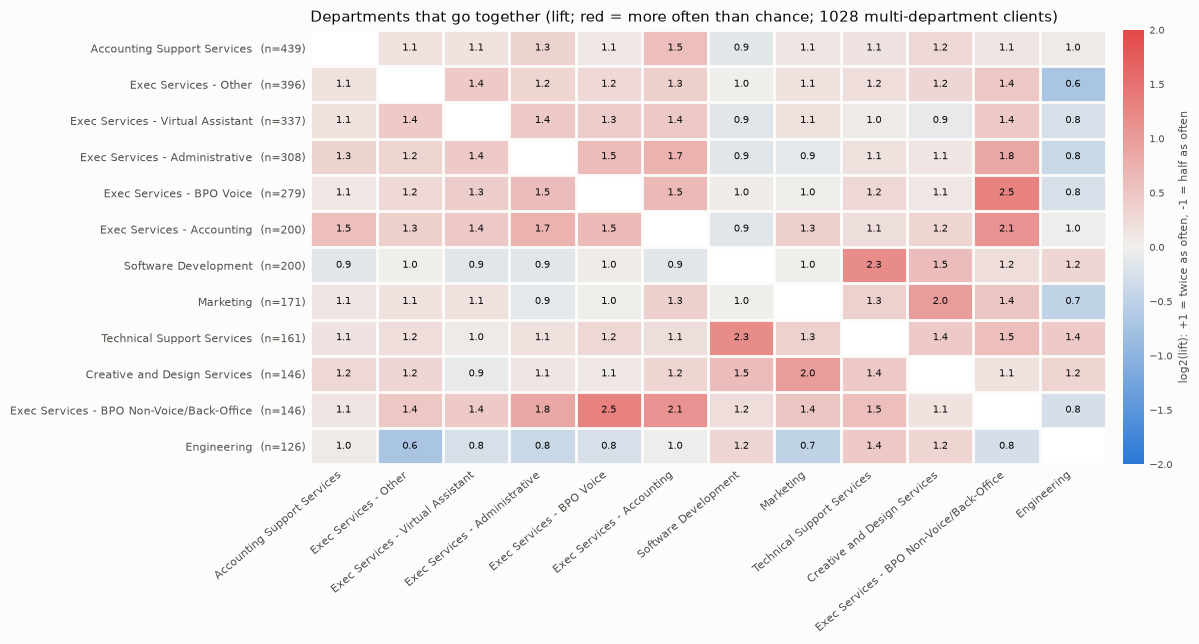

,dept_a,dept_b,clients_both,clients_a,clients_b,pct_a_with_b,pct_b_with_a,lift
0,Sales,Human Resources,11,34,29,0.324,0.379,11.469
1,Exec Services - Ecommerce,Exec Services - Logistics and Supply Chain,16,59,29,0.271,0.552,9.613
2,Lead Generation,Human Resources,10,38,29,0.263,0.345,9.328
3,SQA Services,Exec Services - IT Software Development,10,58,21,0.172,0.476,8.440
4,Lead Generation,Sales,10,38,34,0.263,0.294,7.957
5,Exec Services - Human Resources,Human Resources,13,60,29,0.217,0.448,7.680
6,Product Development,Exec Services - BPO Travel/Hospitality,13,63,32,0.206,0.406,6.629
7,Exec Services - BPO Workforce Management,Exec Services - BPO Voice (Sales) Specialist,11,82,21,0.134,0.524,6.567
8,Exec Services - BPO Workforce Management,Human Resources,15,82,29,0.183,0.517,6.484
9,Exec Services - Human Resources,Exec Services - Recruitment,14,60,37,0.233,0.378,6.483


In [11]:
out.plot_related(B); plt.show()
display(B["related_pairs"].head(25))

In [12]:
# Do clients that branch early grow more / churn less? (landmark comparison within seat bands; association, not cause)
display(B["growth_by_branch"])

accounts  n_eligible_10  \
hc_band   branch_status                                     
1-2 seats New dept by day 365          186            150   
          No new dept by day 365       748            622   
3-4 seats New dept by day 365          137            109   
          No new dept by day 365        86             75   
5-9 seats New dept by day 365          129            102   
          No new dept by day 365        36             26   
10+ seats New dept by day 365           78              0   
          No new dept by day 365        11              0   

                                  pct_reached_10_next_year  n_eligible_churn  \
hc_band   branch_status                                                        
1-2 seats New dept by day 365                        0.000               153   
          No new dept by day 365                     0.002               622   
3-4 seats New dept by day 365                        0.046               109   
          No new dept by day 365                     0.040                75   
5-9 seats New dept by day 365                        0.216               107   
          No new dept by day 365                     0.346                29   
10+ seats New dept by day 365                          NaN                66   
          No new dept by day 365                       NaN                10   

                                  pct_churned_next_year  
hc_band   branch_status                                  
1-2 seats New dept by day 365                     0.261  
          No new dept by day 365                  0.289  
3-4 seats New dept by day 365                     0.073  
          No new dept by day 365                  0.093  
5-9 seats New dept by day 365                     0.093  
          No new dept by day 365                  0.034  
10+ seats New dept by day 365                     0.045  
          No new dept by day 365                  0.300

## 4. Data checks

In [13]:
staff = res["merged"]["staff"]
print("Where each staffer's department (JP Category) comes from:")
display(staff["role_group_source"].value_counts(dropna=False))
s = B["sensitivity_stats"]
print(f"Department join check: start -> next shares on certain-only rows correlate {s['correlation']:.2f} with the main table "
      f"({s['transitions_compared']} transitions compared)")
display(B["sensitivity"])
print("Accounts excluded as non-client (review: is any of these actually a client?)")
display(F["excluded_accounts"].head(20))
print("Workbook:", res["workbook"])

Where each staffer's role group comes from:


role_group_source
Department                9127
JP Category               6348
none                      2724
Designation (inferred)    2169
<NA>                       401
Name: count, dtype: Int64

Department join check: start -> next shares on certain-only rows correlate 0.79 with the main table (13 transitions compared)


,start_dept,first_new_dept,start_dept_accounts,start_dept_branched,accounts_branching_to_dept,pct_of_branched,certain_only_accounts_branching_to_dept,certain_only_pct_of_branched
0,Exec Services - Other,Accounting Support Services,286,115,21,0.183,16,0.327
1,Accounting Support Services,Exec Services - Administrative,475,142,18,0.127,9,0.094
2,Exec Services - Administrative,Accounting Support Services,141,58,18,0.310,13,0.317
3,Accounting Support Services,Exec Services - Other,475,142,18,0.127,16,0.167
4,Software Development,SQA Services,150,57,16,0.281,7,0.259
5,Accounting Support Services,Exec Services - Accounting,475,142,15,0.106,11,0.115
6,Exec Services - Virtual Assistant,Accounting Support Services,192,68,13,0.191,6,0.122
7,Exec Services - Other,Exec Services - Virtual Assistant,286,115,12,0.104,6,0.122
8,Accounting Support Services,Exec Services - Virtual Assistant,475,142,11,0.077,7,0.073
9,Exec Services - Virtual Assistant,Exec Services - Other,192,68,10,0.147,6,0.122


Accounts excluded as non-client (review: is any of these actually a client?)


,Shortcode,total_hires,hub_share
674,CSTREENGAGE,5395,0.03
518,CLOUDSTAFF,2303,0.19
667,CSTALENTOPS,170,1.0
584,CSAPAC,77,0.96
609,CSENDP,73,1.0
597,CSCONCIERGE,66,1.0
582,CSAMER,58,1.0
606,CSDEVSTAFFX,51,0.98
632,CSMKTG,49,1.0
639,CSOPTICORE,46,1.0


Workbook: C:\Users\Alfonso(FonsoP)Panli\Desktop\Projects\Client Propensity\Data\2026-11-12_Client_Propensity_Scorecards.xlsx


## 5. Executive summary

Charts for a leadership audience. Each reads on its own, and the dashed line marks the average for all clients.

**Department expansion**
1. **By industry:** how many clients add a new department, where they usually start, and what they most often add first.
2. **By starting department:** what clients add after their first department.
3. **By industry and country:** the same as 1, split by where the client is based.

**Seat growth**
4. **Which new clients grow:** chance a brand-new client (1-2 staff) reaches 5+ seats within a year, by industry and country (model estimate).
5. **What makes a new client grow:** traits that raise or lower that chance, compared with an average new client.
6. **By starting department:** share of clients launching with 1-4 staff that reached 5+ seats within 2 years (actual history).
7. **By industry and country:** the same as 6.

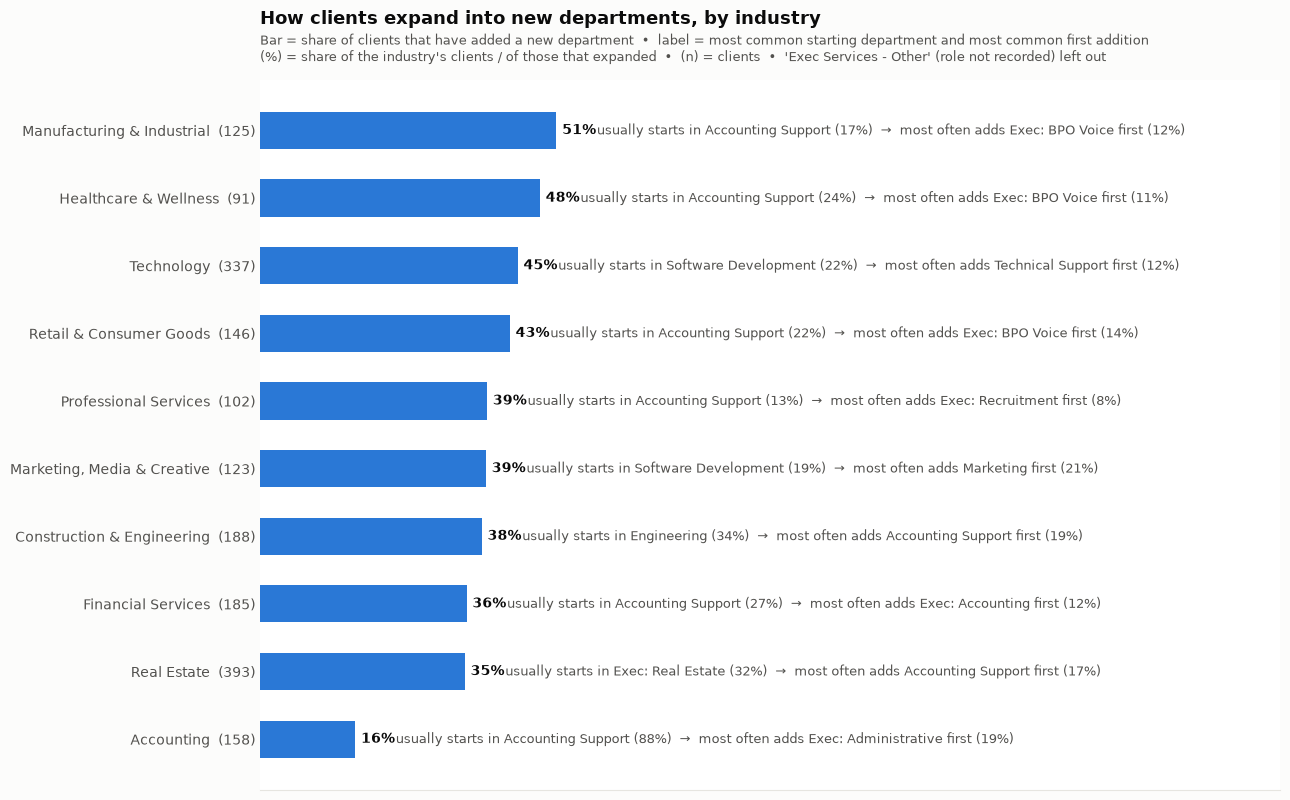

In [14]:
out.plot_exec_expansion_paths(F); plt.show()

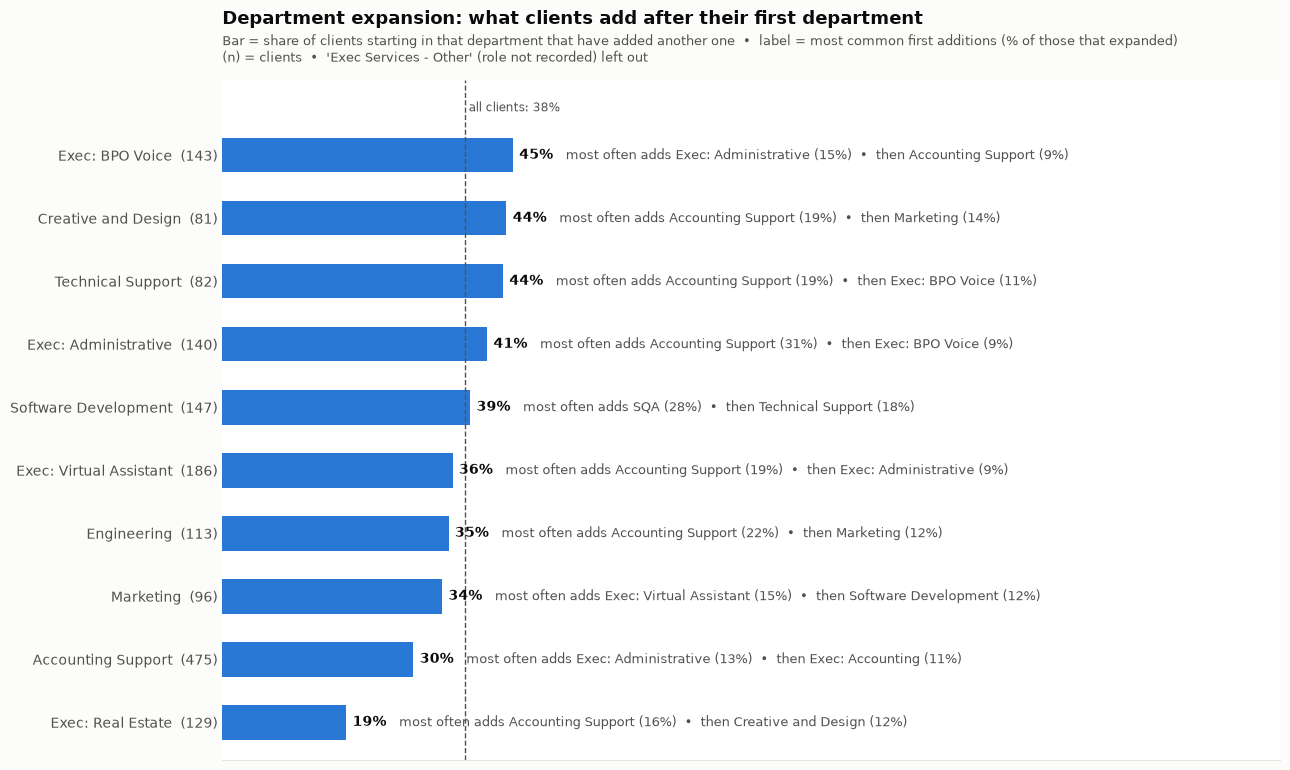

In [15]:
out.plot_exec_dept_paths(F); plt.show()

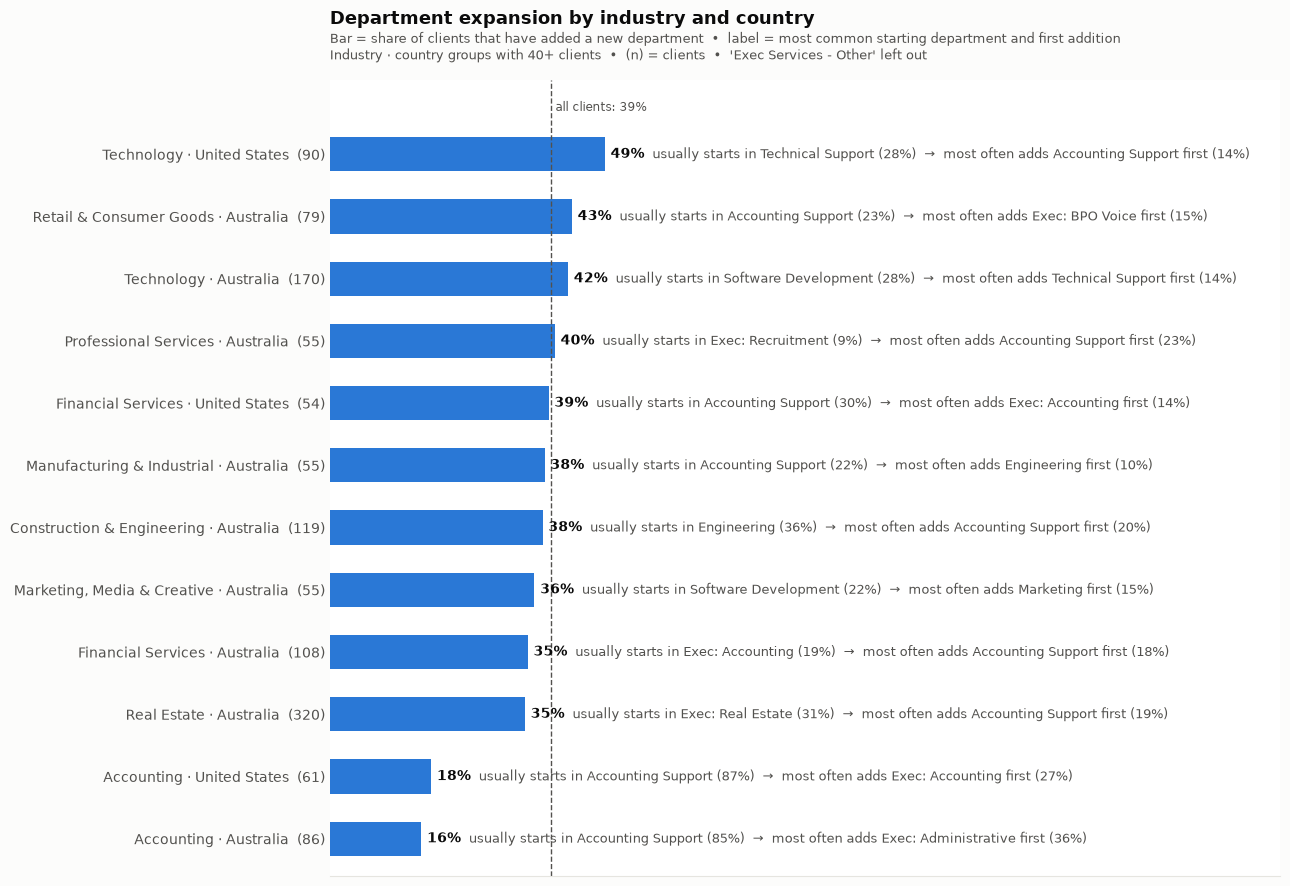

In [16]:
out.plot_exec_profile_paths(F); plt.show()

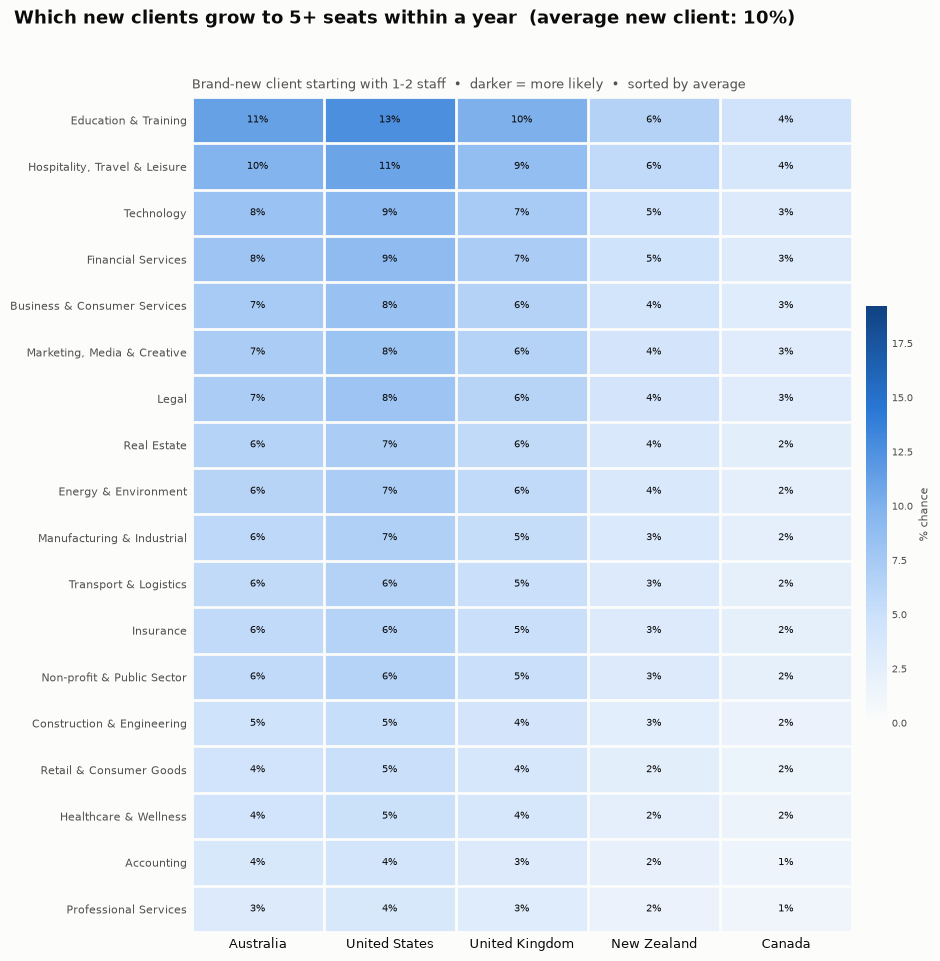

In [17]:
out.plot_exec_growth_heatmap(P); plt.show()

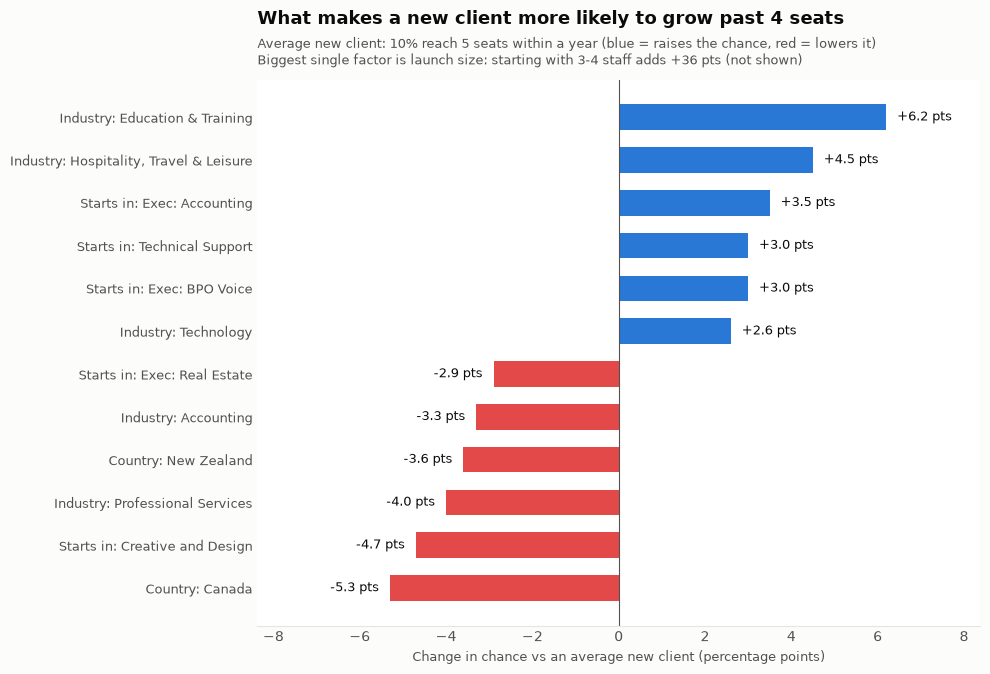

In [18]:
out.plot_exec_growth_drivers(P); plt.show()

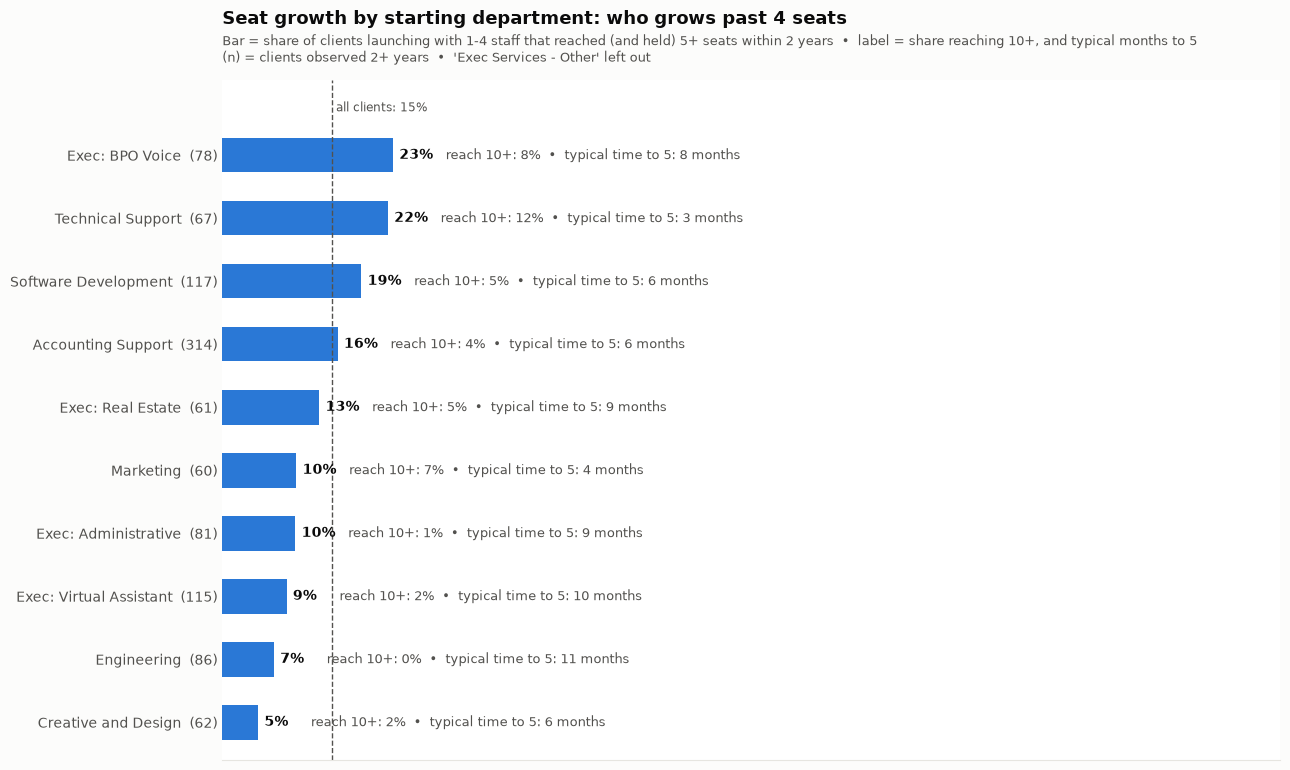

In [19]:
out.plot_exec_dept_seat_growth(F); plt.show()

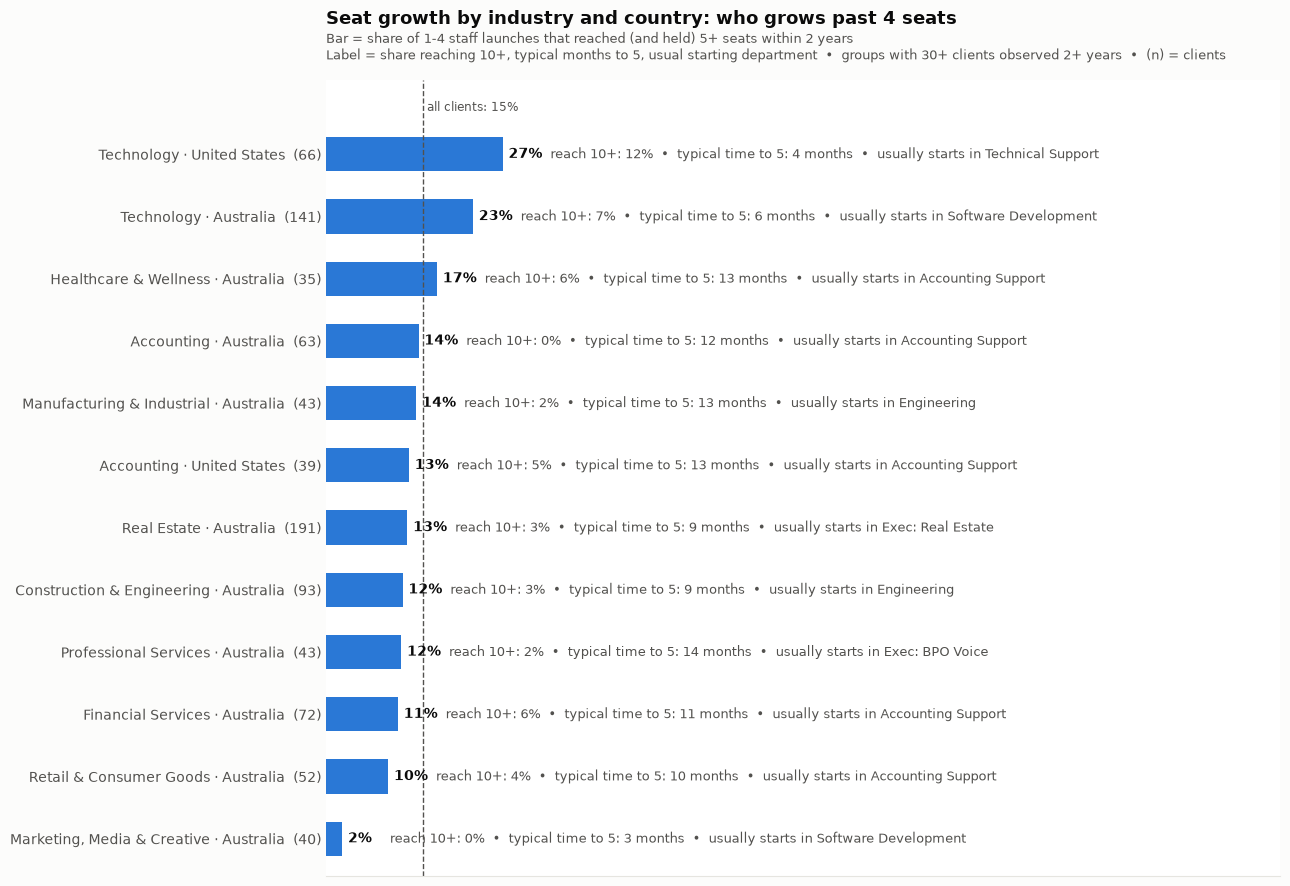

In [20]:
out.plot_exec_profile_seat_growth(F); plt.show()